# HSA_Cam_B_005.py
This file uses the LHHW_Model of kinetics to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_003.py is the model. This uses homoscedastic noise.

## First try to actually infer the model

### Plan:
* generate data
* instantiate the model
* infer the model using ADVI
* check HDIs
* select next experiment at highest HDI

### Results:
* Inference works
* HDIs work
* max HDI strategy does not work

In [1]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import pytensor

import arviz as az
from scipy.optimize import minimize

# pytensor.config.mode = "JAX"

In [2]:
from HSA_Cam_B_003 import (
    SIDX,
    TRUE_PARAMS,
    _kinetics_model,
    input_p,
    bmodel,
)

In [3]:
def post_model_over_T(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_T(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T

In [4]:
T = jnp.array([560, 570, 580], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array([4, 5, 6], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array([1], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array([1000], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array([0.5], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
print(r)
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
print(r_obs)

[[9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [1.24968760e+00 1.24968760e+00 0.00000000e+00 1.24968760e-03
  2.49937519e+00]
 [1.49962512e+00 1.49962512e+00 0.00000000e+00 1.49962512e-03
  2.99925023e+00]]
[[7.61192633e-05]
 [1.16399861e-04]
 [1.72598760e-04]]
[[8.56923350e-05]
 [1.06700571e-04]
 [1.82669424e-04]]


In [5]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    # rel_HDI = HDI / jnp.median(res)
    return -HDI  # -rel_HDI

In [6]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [7]:
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000)

Sampling: [A_h2, A_mix, A_oh, Ea_k, LH2, dH_h2, dH_mix, dH_oh, k0, sigma_r]


In [8]:
sol = minimize(
    max_func,
    jnp.array([555.0, 15.0, 0.5, 1000.0, 0.5]),
    args=(prior_idata, "prior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.atleast_2d(sol.x)
print(proposals)

[[6.e+02 2.e+01 5.e-01 1.e+03 1.e+00]]


In [9]:
Ts = jnp.linspace(500, 600, 100)
test_res = post_model_over_T(proposals[0], prior_idata, key="prior")
true_res = true_model_over_T(proposals[0])

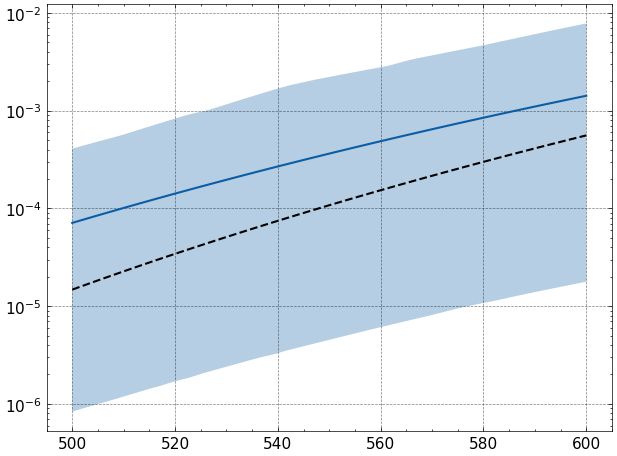

In [10]:
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(Ts, true_res.squeeze(), color="black", linestyle="dashed")
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
plt.yscale("log")

# First Conditioning step

In [11]:
T = jnp.array([proposals[0, 0]], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array([proposals[0, 1]], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array([proposals[0, 2]], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array([proposals[0, 3]], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array([proposals[0, 4]], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5

[[4.99875039e+00 9.99750078e+00 0.00000000e+00 4.99875039e-03
  4.99875039e+00]]


In [12]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [13]:
with model:
    mean_field = pm.fit(n=50000, method="advi")
    # idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Output()

Finished [100%]: Average Loss = 23.967


In [14]:
idata = mean_field.sample(1000)
display(idata)

Inference data with groups:
	> posterior
	> observed_data

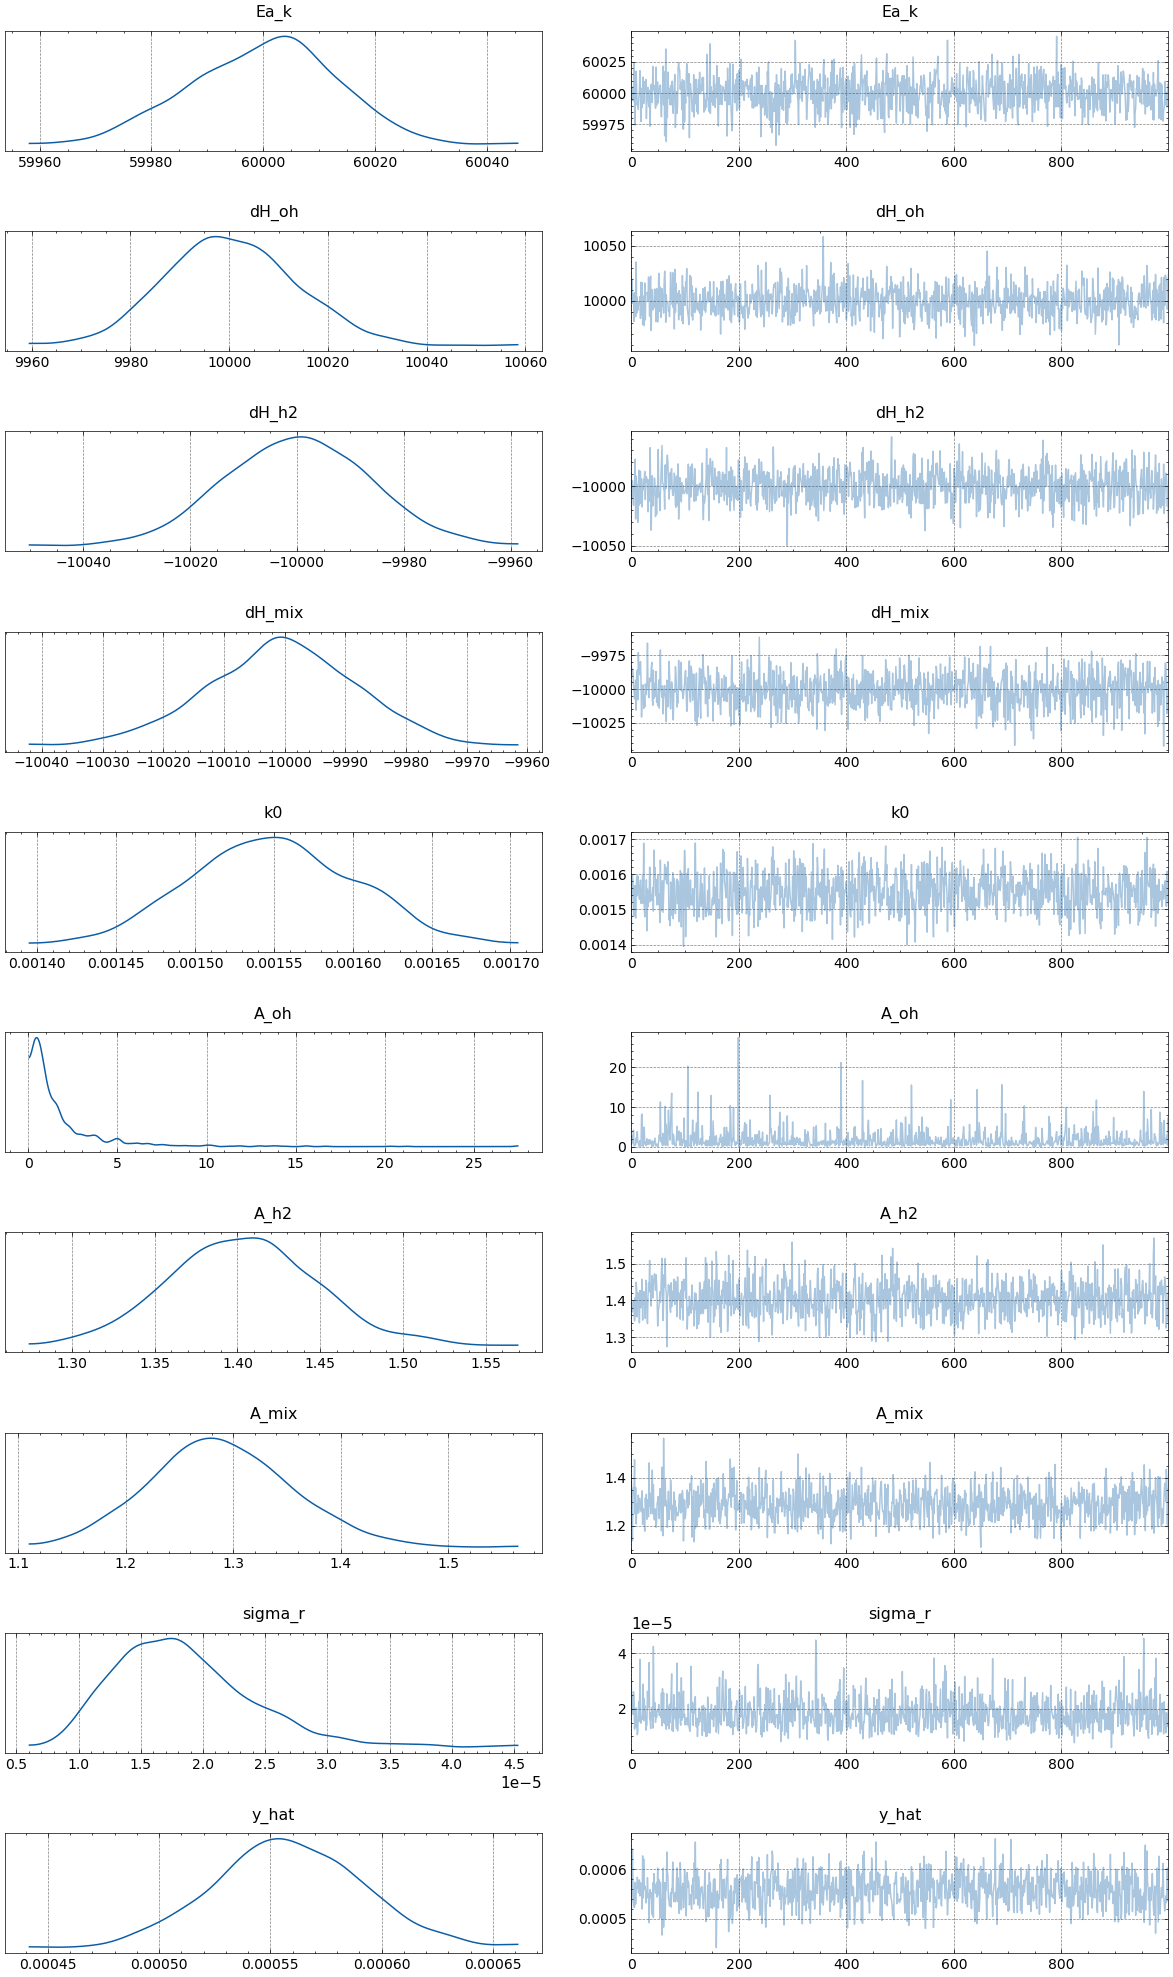

In [15]:
import arviz as az

az.plot_trace(idata)
# az.plot_trace(idata, divergences=False)
plt.show()

In [16]:
test_res = post_model_over_T(proposals[0], idata, key="posterior")
true_res_T = true_model_over_T(proposals[0])

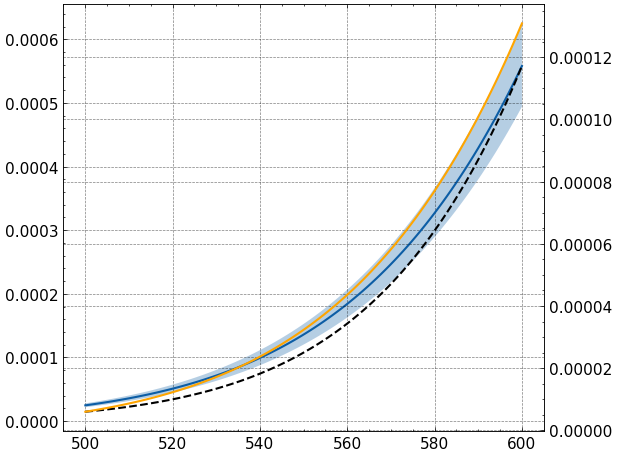

In [17]:
plt.plot(
    Ts,
    test_res.mean(axis=1),
)
plt.plot(
    Ts,
    true_res_T.squeeze(),
    color="black",
    linestyle="--",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

In [18]:
sol = minimize(
    max_func,
    jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)

In [19]:
print(proposals)

[[6.00000000e+02 2.00000000e+01 5.00000000e-01 1.00000000e+03
  1.00000000e+00]
 [6.00000000e+02 2.00000000e+01 8.82085249e-01 1.00000000e+03
  1.00000000e+00]]


In [20]:
test_res = post_model_over_T(proposals[1], idata, key="posterior")
true_res_T = true_model_over_T(proposals[1])

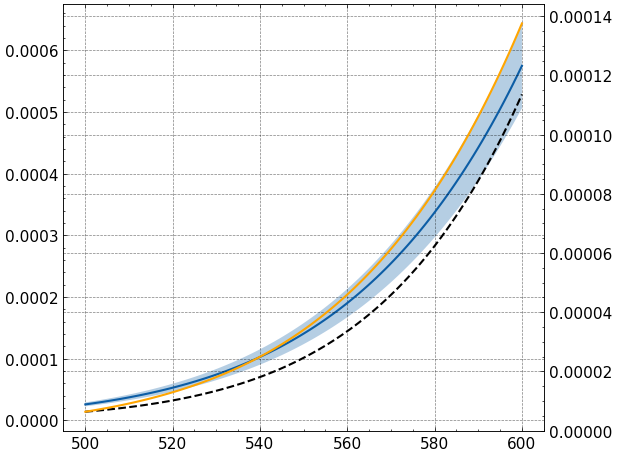

In [21]:
plt.plot(
    Ts,
    test_res.mean(axis=1),
)
plt.plot(
    Ts,
    true_res_T.squeeze(),
    color="black",
    linestyle="--",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

# Second Sampling step

In [22]:
T = jnp.array(proposals[:, 0], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array(proposals[:, 1], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array(proposals[:, 2], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array(proposals[:, 3], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array(proposals[:, 4], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
print(r_obs.shape)

[[4.99875039e+00 9.99750078e+00 0.00000000e+00 4.99875039e-03
  4.99875039e+00]
 [6.38024211e+00 7.23313536e+00 0.00000000e+00 6.38024211e-03
  6.38024211e+00]]
(2, 1)


In [23]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [24]:
with model:
    mean_field = pm.fit(
        n=50000, method="advi", obj_optimizer=pm.adam(learning_rate=0.01)
    )
    # idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Output()

Finished [100%]: Average Loss = 1.267


In [25]:
idata = mean_field.sample(1000)

array([[<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'dH_oh'}>,
        <Axes: title={'center': 'dH_oh'}>],
       [<Axes: title={'center': 'dH_h2'}>,
        <Axes: title={'center': 'dH_h2'}>],
       [<Axes: title={'center': 'dH_mix'}>,
        <Axes: title={'center': 'dH_mix'}>],
       [<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'A_oh'}>,
        <Axes: title={'center': 'A_oh'}>],
       [<Axes: title={'center': 'A_h2'}>,
        <Axes: title={'center': 'A_h2'}>],
       [<Axes: title={'center': 'A_mix'}>,
        <Axes: title={'center': 'A_mix'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>],
       [<Axes: title={'center': 'y_hat'}>,
        <Axes: title={'center': 'y_hat'}>]], dtype=object)

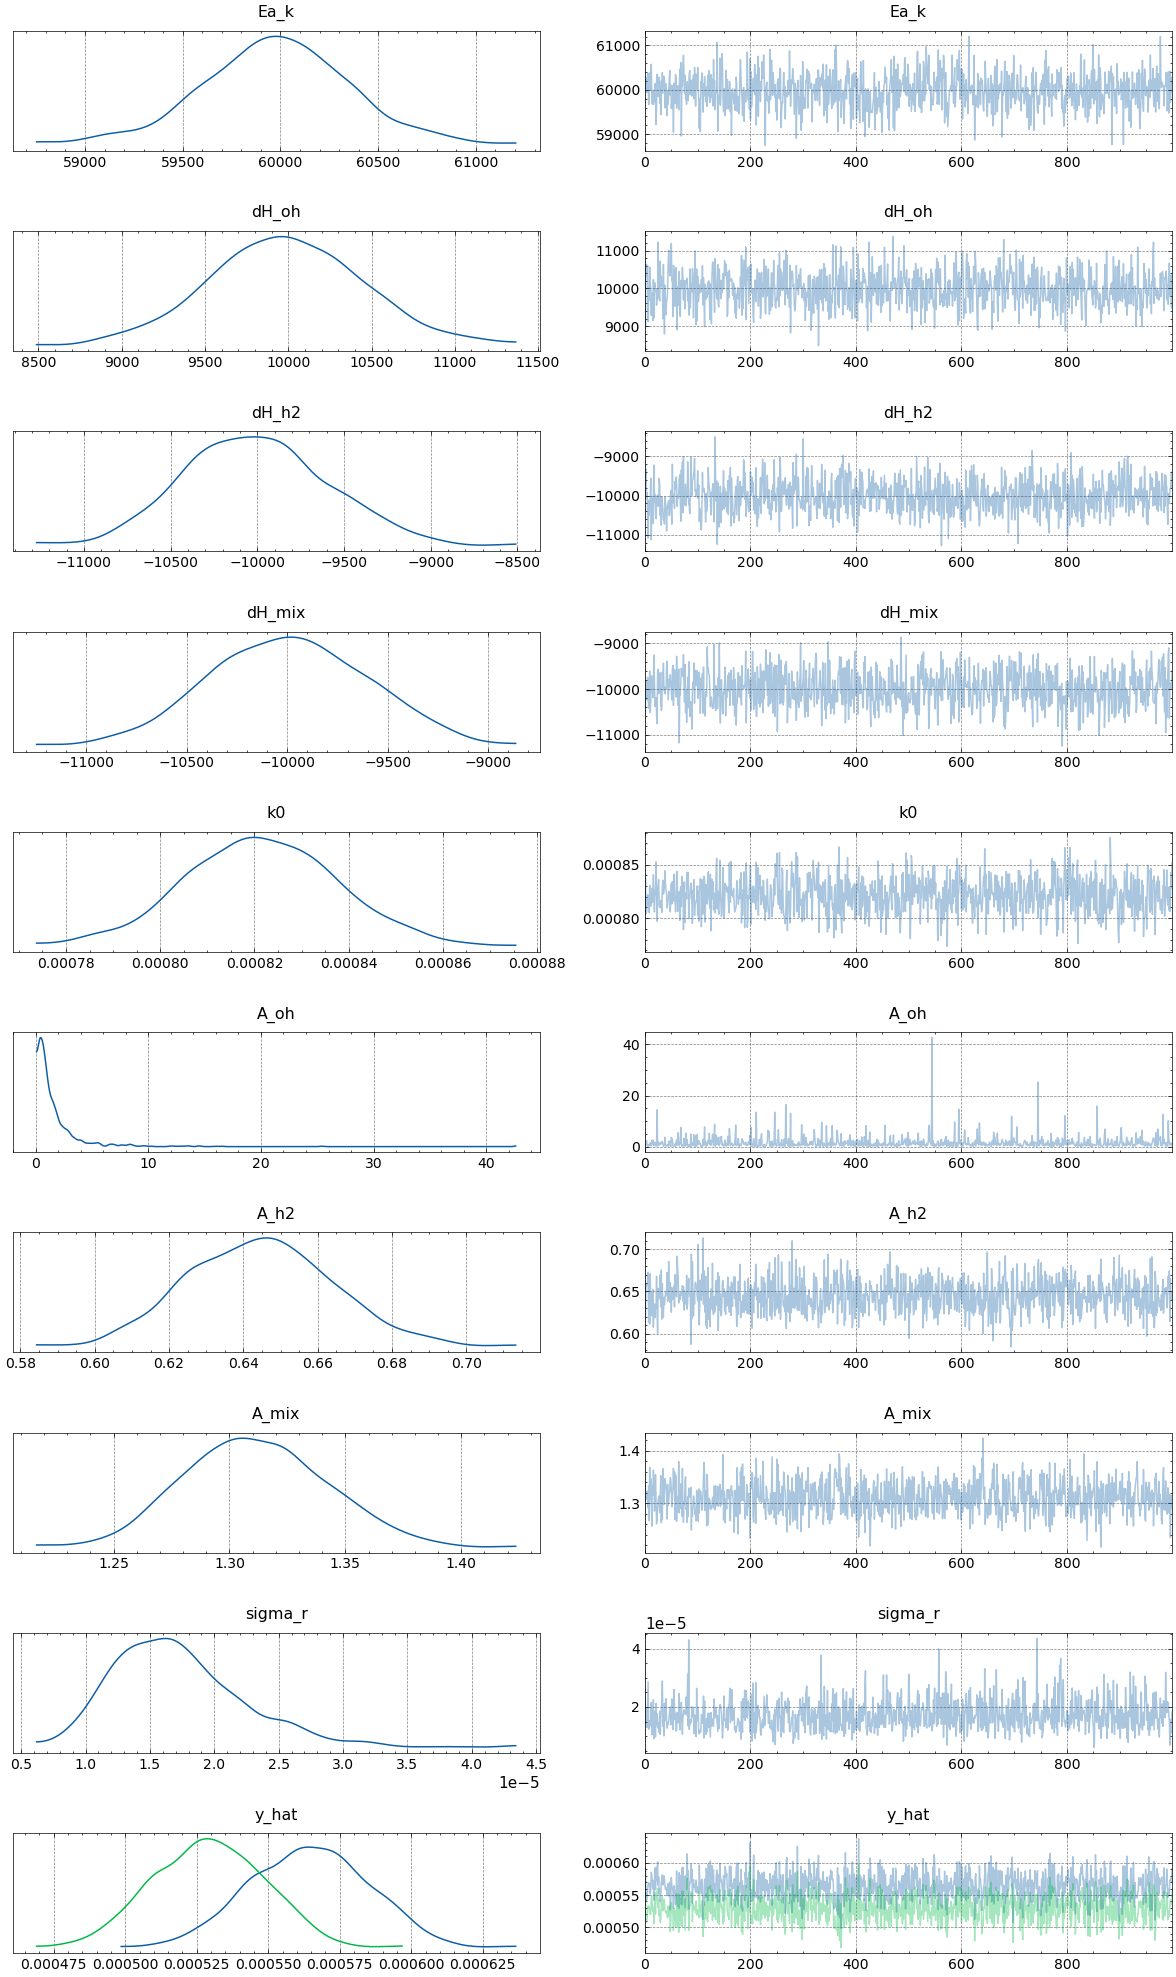

In [26]:
az.plot_trace(idata, divergences=False)

In [27]:
# get relative ESS
az.ess(idata)

<xarray.Dataset> Size: 112B
Dimensions:      (y_hat_dim_0: 2, y_hat_dim_1: 1)
Coordinates:
  * y_hat_dim_0  (y_hat_dim_0) int64 16B 0 1
  * y_hat_dim_1  (y_hat_dim_1) int64 8B 0
Data variables:
    Ea_k         float64 8B 863.7
    dH_oh        float64 8B 931.3
    dH_h2        float64 8B 868.9
    dH_mix       float64 8B 908.6
    k0           float64 8B 929.8
    A_oh         float64 8B 1.014e+03
    A_h2         float64 8B 996.0
    A_mix        float64 8B 914.6
    sigma_r      float64 8B 845.6
    y_hat        (y_hat_dim_0, y_hat_dim_1) float64 16B 978.3 971.9

In [28]:
test_res = post_model_over_T(proposals[1], idata, key="posterior")
true_res = true_model_over_T(proposals[1])

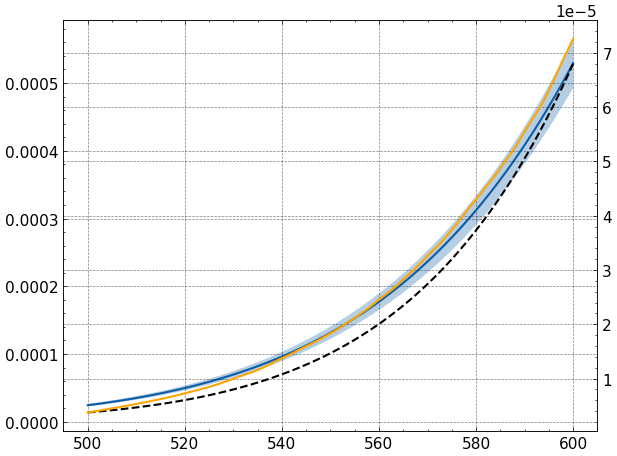

In [29]:
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

In [30]:
sol = minimize(
    max_func,
    jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 8.82085249e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 5.66695173e-01, 1.00000000e+03,
        9.99999987e-01]])

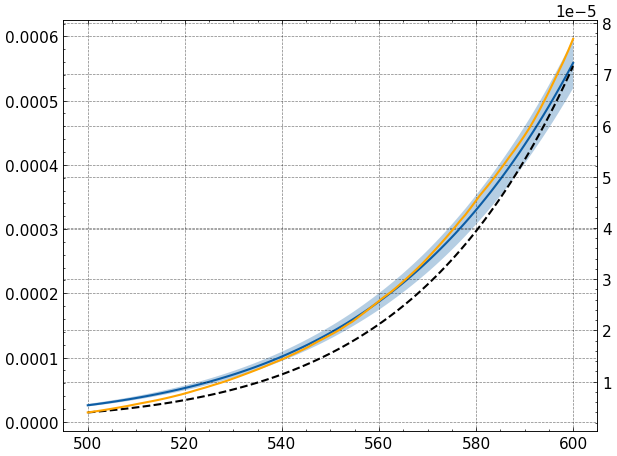

In [31]:
test_res = post_model_over_T(proposals[2], idata, key="posterior")
true_res = true_model_over_T(proposals[2])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

# third conditioning step

In [32]:
T = jnp.array(proposals[:, 0], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array(proposals[:, 1], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array(proposals[:, 2], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array(proposals[:, 3], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array(proposals[:, 4], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
print(r_obs.shape)

[[4.99875039e+00 9.99750078e+00 0.00000000e+00 4.99875039e-03
  4.99875039e+00]
 [6.38024211e+00 7.23313536e+00 0.00000000e+00 6.38024211e-03
  6.38024211e+00]
 [5.31121433e+00 9.37226001e+00 0.00000000e+00 5.31121433e-03
  5.31121433e+00]]
(3, 1)


In [33]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [34]:
with model:
    mean_field = pm.fit(
        n=50000, method="advi", obj_optimizer=pm.adam(learning_rate=0.01)
    )
    # idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Output()

Finished [100%]: Average Loss = -7.8284


In [35]:
idata = mean_field.sample(1000)

array([[<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'dH_oh'}>,
        <Axes: title={'center': 'dH_oh'}>],
       [<Axes: title={'center': 'dH_h2'}>,
        <Axes: title={'center': 'dH_h2'}>],
       [<Axes: title={'center': 'dH_mix'}>,
        <Axes: title={'center': 'dH_mix'}>],
       [<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'A_oh'}>,
        <Axes: title={'center': 'A_oh'}>],
       [<Axes: title={'center': 'A_h2'}>,
        <Axes: title={'center': 'A_h2'}>],
       [<Axes: title={'center': 'A_mix'}>,
        <Axes: title={'center': 'A_mix'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>],
       [<Axes: title={'center': 'y_hat'}>,
        <Axes: title={'center': 'y_hat'}>]], dtype=object)

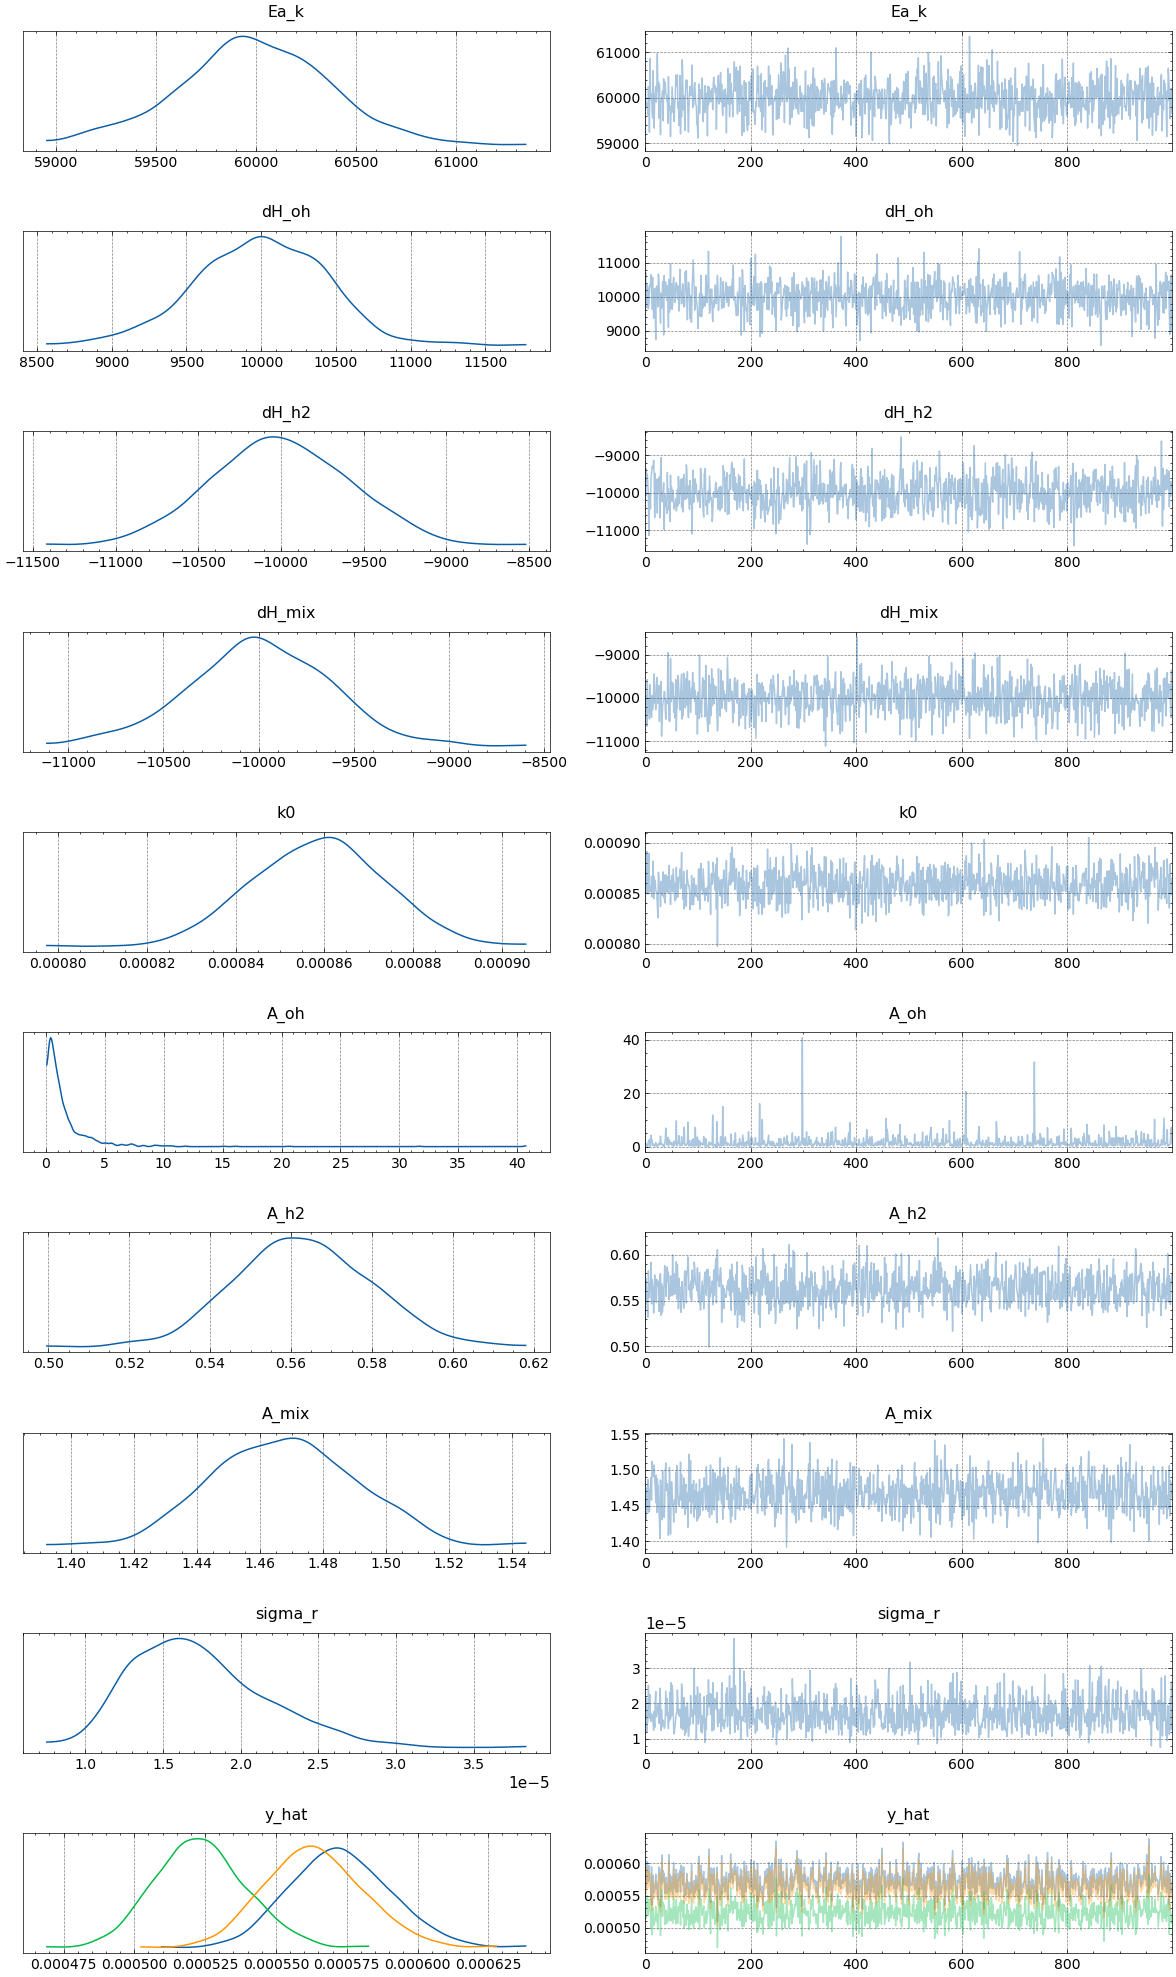

In [36]:
az.plot_trace(idata, divergences=False)

In [37]:
test_res = post_model_over_T(proposals[2], idata, key="posterior")
true_res = true_model_over_T(proposals[2])

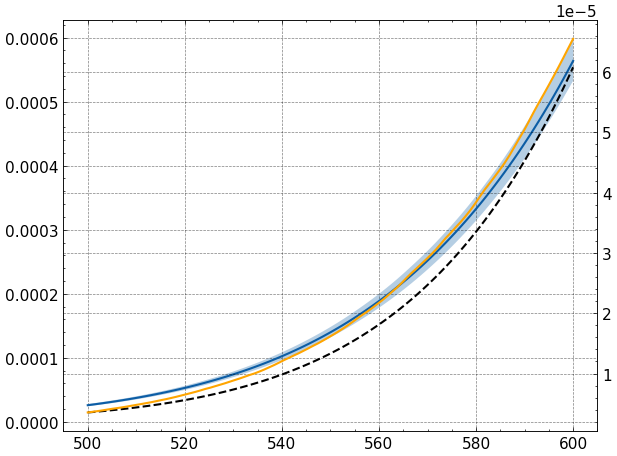

In [38]:
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

In [39]:
sol = minimize(
    max_func,
    jnp.array([555.0, 15.0, 1.0, 1000.0, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 8.82085249e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 5.66695173e-01, 1.00000000e+03,
        9.99999987e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000005e-01, 1.00000000e+03,
        1.00000000e+00]])

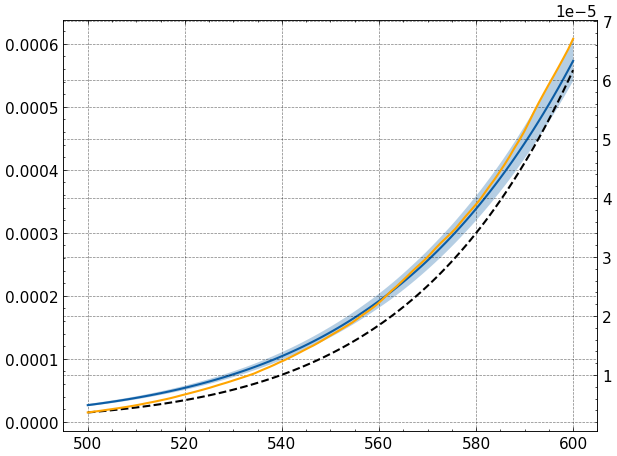

In [40]:
test_res = post_model_over_T(proposals[3], idata, key="posterior")
true_res = true_model_over_T(proposals[3])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

# Fourth Conditioning Step

In [41]:
T = jnp.array(proposals[:, 0], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array(proposals[:, 1], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array(proposals[:, 2], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array(proposals[:, 3], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array(proposals[:, 4], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
print(r_obs.shape)

[[4.99875039e+00 9.99750078e+00 0.00000000e+00 4.99875039e-03
  4.99875039e+00]
 [6.38024211e+00 7.23313536e+00 0.00000000e+00 6.38024211e-03
  6.38024211e+00]
 [5.31121433e+00 9.37226001e+00 0.00000000e+00 5.31121433e-03
  5.31121433e+00]
 [4.99875039e+00 9.99750078e+00 0.00000000e+00 4.99875039e-03
  4.99875039e+00]]
(4, 1)


In [42]:
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)

In [43]:
with model:
    mean_field = pm.fit(n=50000, method="advi")
    # idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Output()

Finished [100%]: Average Loss = -2.6443


In [44]:
idata = mean_field.sample(1000)

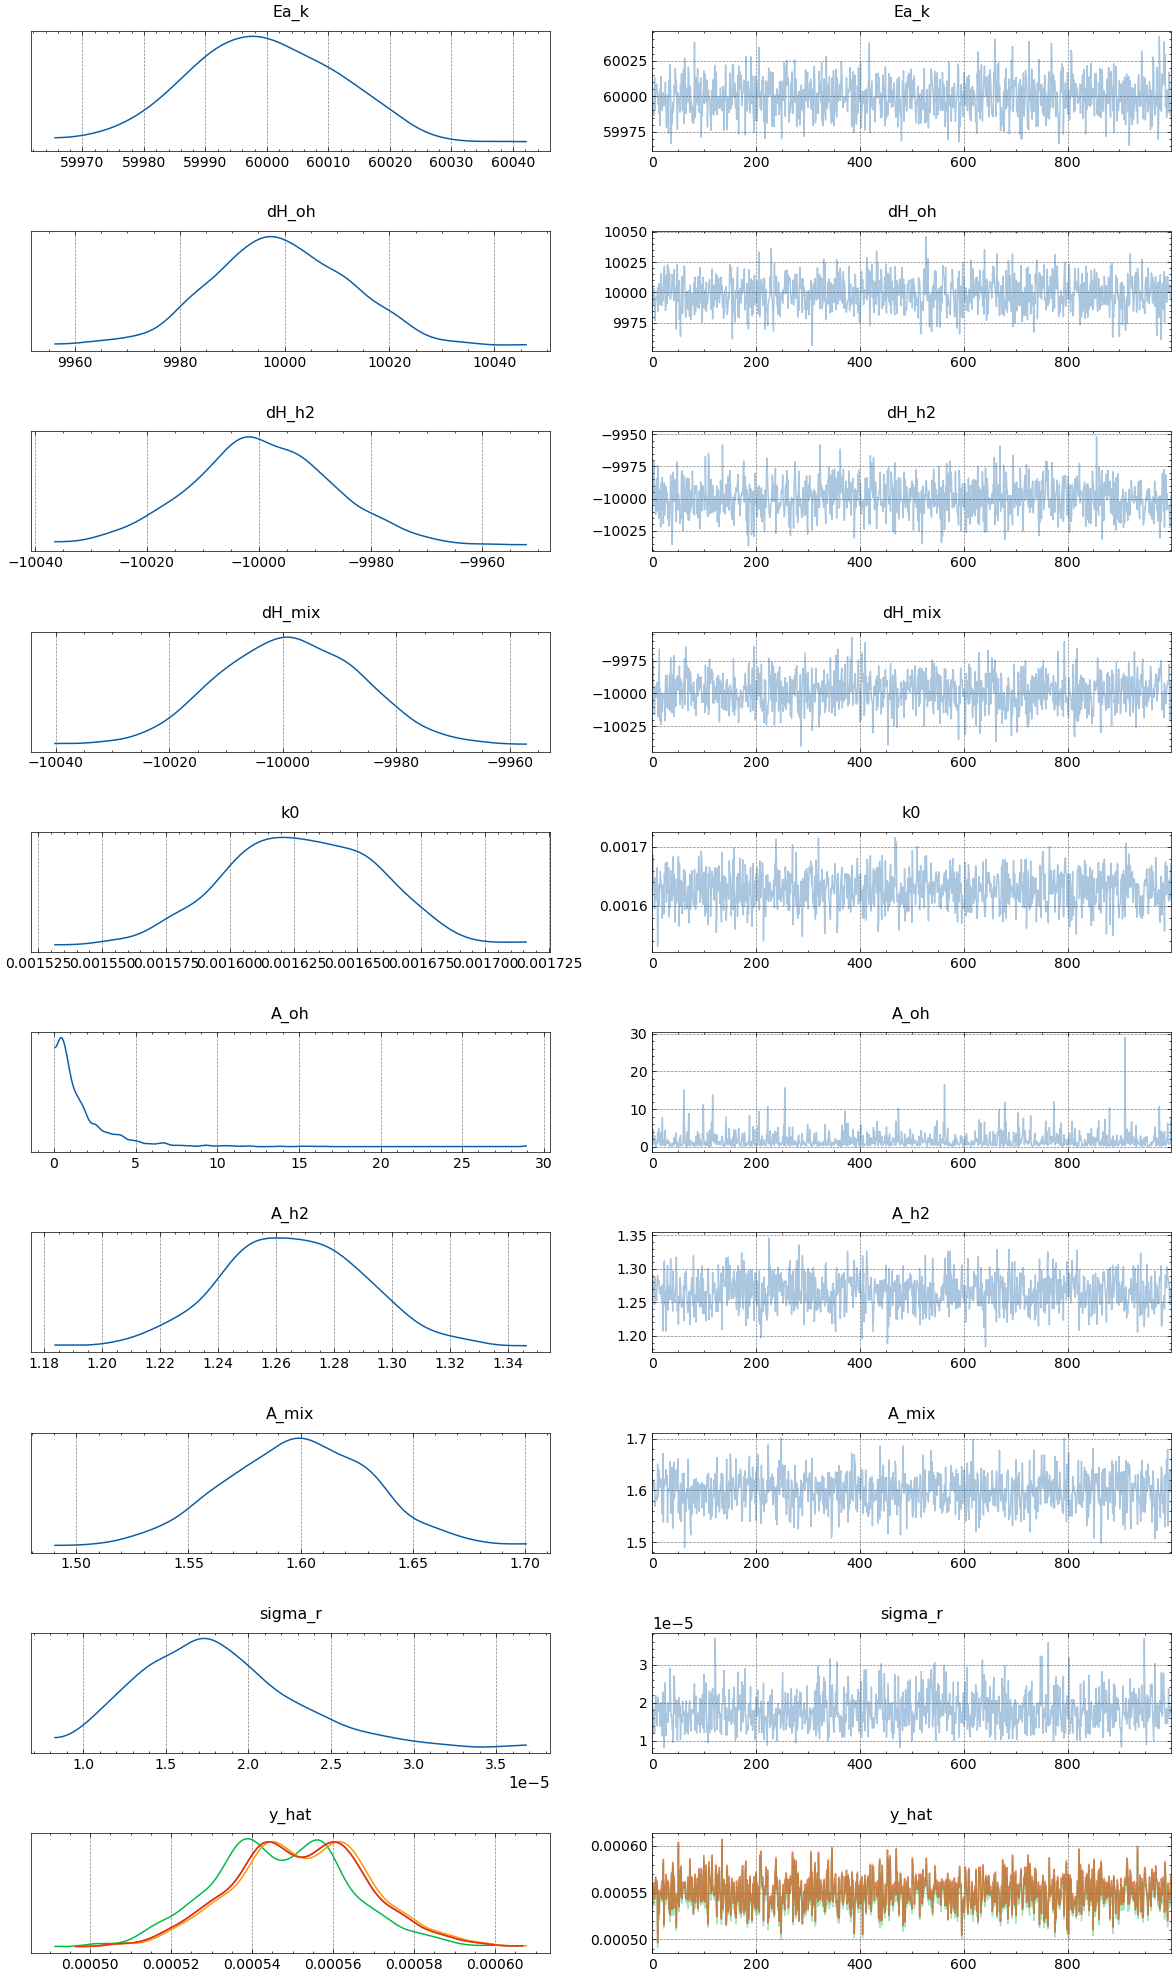

In [45]:
az.plot_trace(idata, divergences=False)
plt.show()

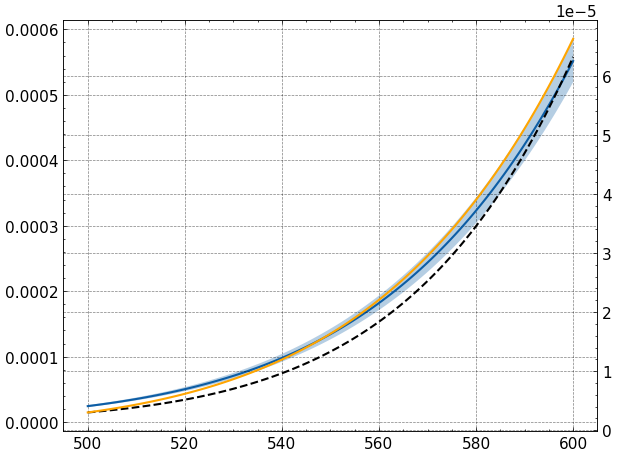

In [46]:
test_res = post_model_over_T(proposals[3], idata, key="posterior")
true_res = true_model_over_T(proposals[3])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

In [47]:
sol = minimize(
    max_func,
    jnp.array([555.0, 10.0, 1.0, 100, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 8.82085249e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 5.66695173e-01, 1.00000000e+03,
        9.99999987e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000005e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00]])

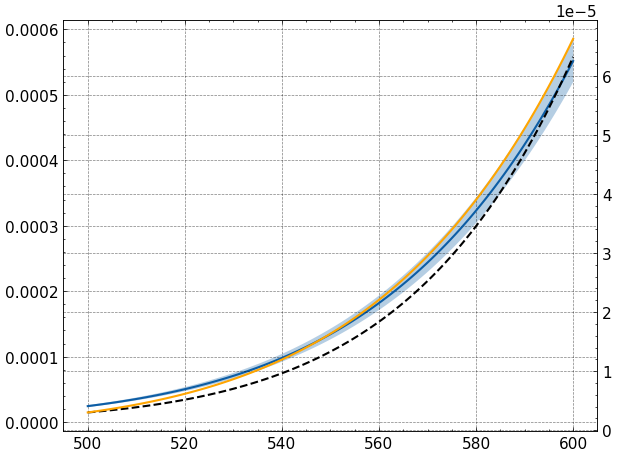

In [48]:
test_res = post_model_over_T(proposals[4], idata, key="posterior")
true_res = true_model_over_T(proposals[4])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

# Fifth Sampling Step

In [49]:
T = jnp.array(proposals[:, 0], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array(proposals[:, 1], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array(proposals[:, 2], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array(proposals[:, 3], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array(proposals[:, 4], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
print(r)
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
print(r_obs)

[[0.00055803]
 [0.0005284 ]
 [0.00055369]
 [0.00055803]
 [0.00055803]]
[[0.00056494]
 [0.00052353]
 [0.00054213]
 [0.00055924]
 [0.00055607]]


In [50]:
with model:
    mean_field = pm.fit(n=50000, method="advi")
    # idata = pm.sample(4000, tune=1000, chains=4, target_accept=0.9)

Output()

Finished [100%]: Average Loss = -2.6499


In [51]:
idata = mean_field.sample(1000)

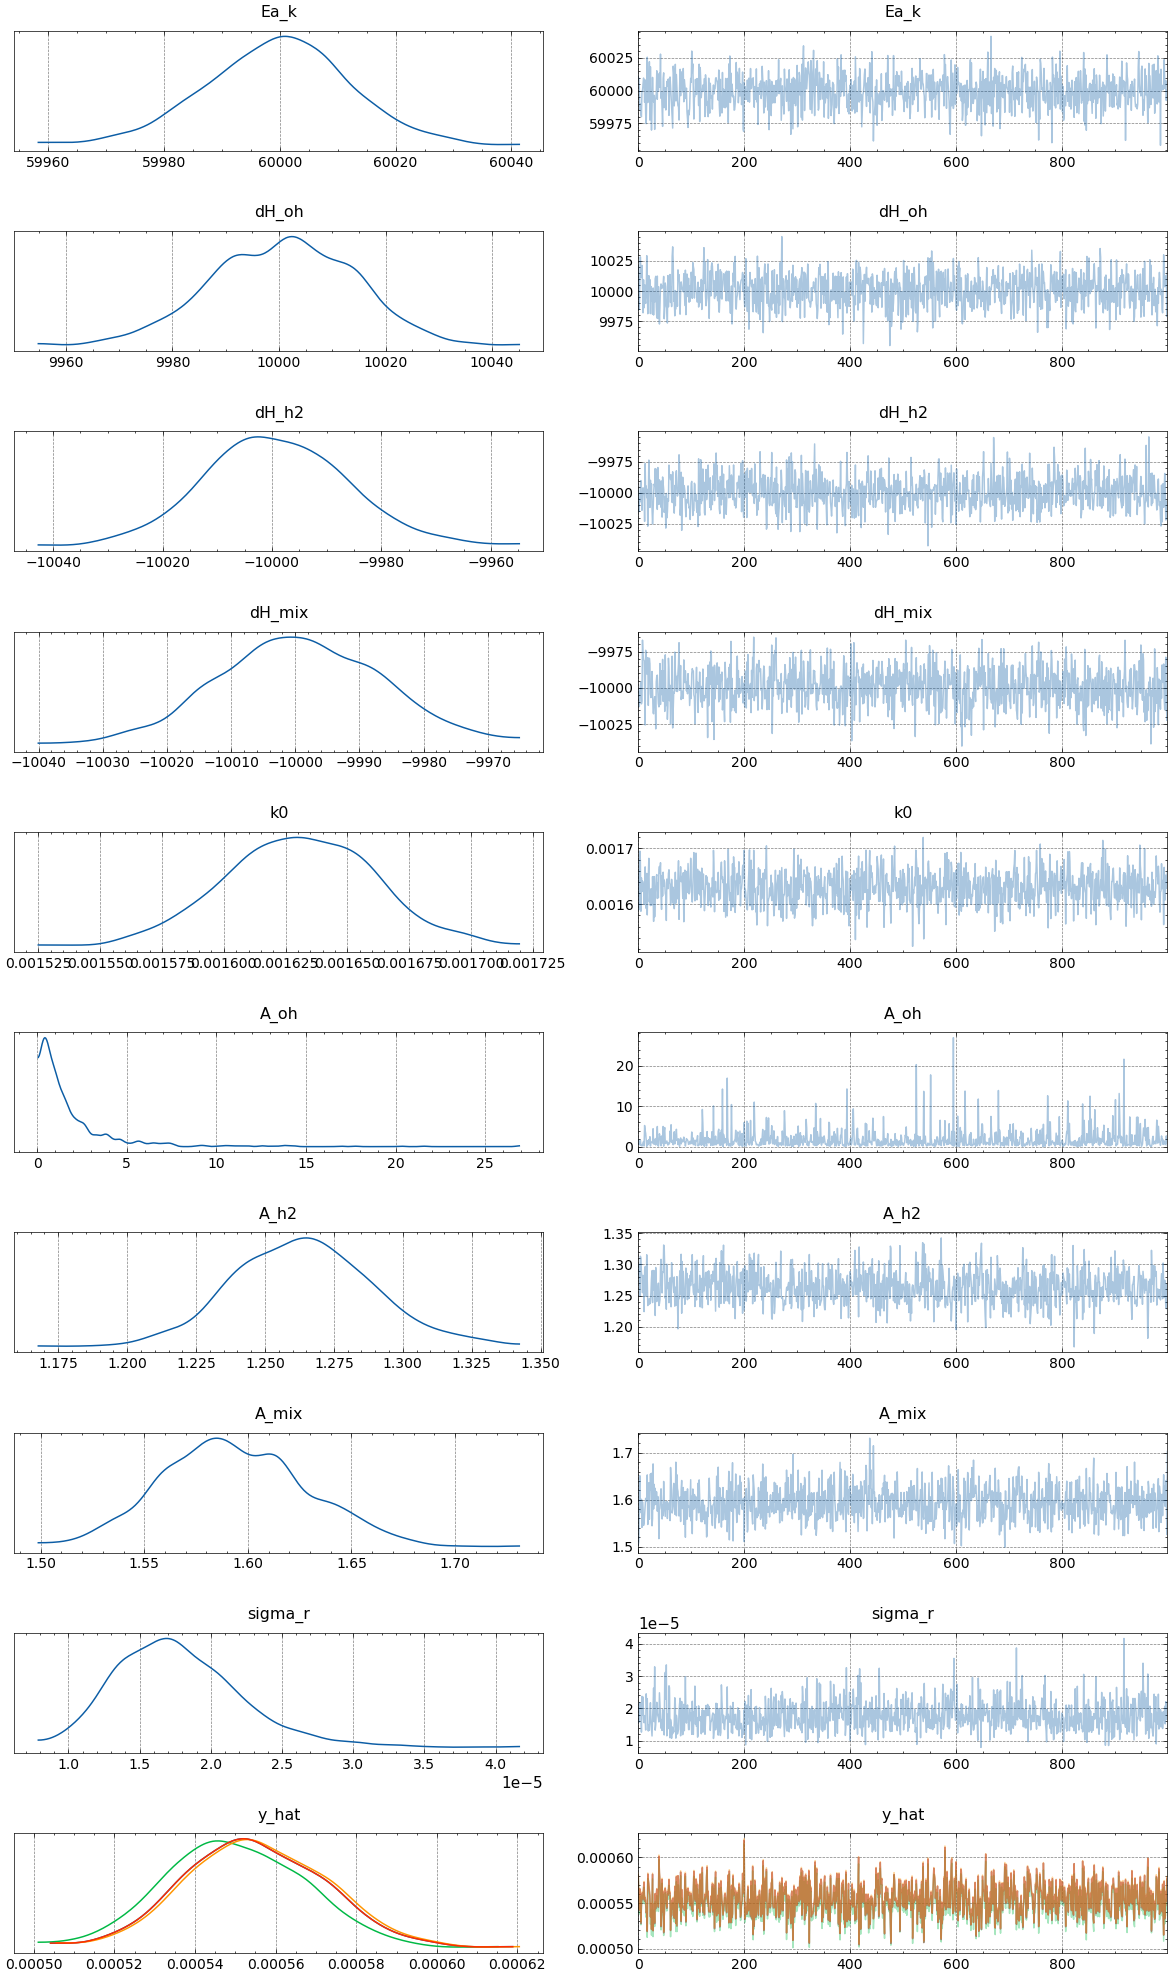

In [52]:
az.plot_trace(idata, divergences=False)
plt.show()

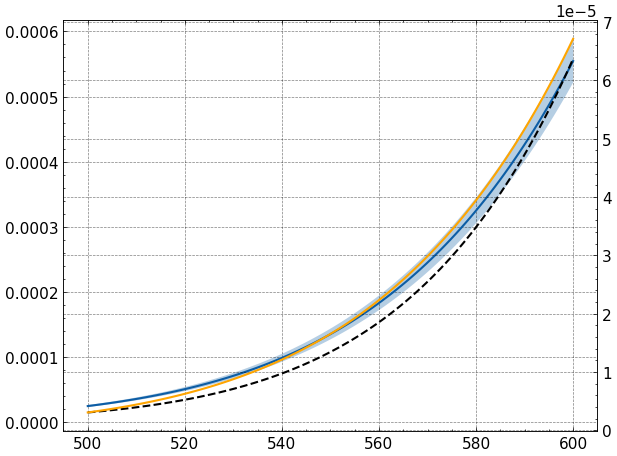

In [53]:
test_res = post_model_over_T(proposals[4], idata, key="posterior")
true_res = true_model_over_T(proposals[4])
plt.plot(Ts, test_res.mean(axis=1))
plt.plot(
    Ts,
    true_res.squeeze(),
    color="black",
    linestyle="dashed",
)
plt.fill_between(
    x=Ts,
    y1=np.percentile(test_res, 2.5, axis=1),
    y2=np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    zorder=0,
)
ax = plt.gca()
ax2 = ax.twinx()
ax2.plot(
    Ts,
    np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1),
    color="orange",
)

In [54]:
sol = minimize(
    max_func,
    jnp.array([555.0, 10.0, 1.0, 100, 0.5]),
    args=(idata, "posterior"),
    bounds=((500, 600), (2, 20), (0.5, 2), (1, 1000), (0.1, 1)),
    method="Nelder-Mead",
)
proposals = np.append(proposals, np.atleast_2d(sol.x), axis=0)
display(proposals)

array([[6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 8.82085249e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 5.66695173e-01, 1.00000000e+03,
        9.99999987e-01],
       [6.00000000e+02, 2.00000000e+01, 5.00000005e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 5.00000000e-01, 1.00000000e+03,
        1.00000000e+00],
       [6.00000000e+02, 2.00000000e+01, 5.33313143e-01, 1.00000000e+03,
        1.00000000e+00]])

In [55]:
display(pm.summary(idata, hdi_prob=0.95))

arviz - WARNING - Shape validation failed: input_shape: (1, 1000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Ea_k,59999.456,12.380,59974.754,60024.319,0.380,0.302,1059.0,975.0,NaN
dH_oh,10000.628,13.293,9973.427,10024.657,0.428,0.303,956.0,743.0,NaN
dH_h2,-9999.353,12.939,-10026.895,-9976.061,0.405,0.298,1017.0,972.0,NaN
dH_mix,-9999.424,12.987,-10025.637,-9974.003,0.421,0.295,947.0,936.0,NaN
k0,0.002,0.000,0.002,0.002,0.000,0.000,988.0,916.0,NaN
A_oh,1.877,2.492,0.031,6.324,0.078,0.196,971.0,980.0,NaN
A_h2,1.264,0.025,1.215,1.317,0.001,0.001,707.0,818.0,NaN
A_mix,1.594,0.035,1.529,1.665,0.001,0.001,872.0,876.0,NaN
sigma_r,0.000,0.000,0.000,0.000,0.000,0.000,1092.0,838.0,NaN
"y_hat[0, 0]",0.001,0.000,0.001,0.001,0.000,0.000,935.0,847.0,NaN
